# Phase 3 — Deep Learning & Neural Networks
## Notebook 02: TensorFlow & Keras Fundamentals

### Executive Overview & Strategic Framework Positioning
TensorFlow, developed by the Google Brain team and powering production AI infrastructure at Google, Uber, Airbnb, and thousands of enterprises, represents the quintessential **graph-first, deployment-centric deep learning framework**. While PyTorch has become the prevailing standard for academic research and Generative AI foundation modeling, TensorFlow—especially when paired with modern **Keras 3**—remains the gold standard for **production-grade serving, high-throughput enterprise pipelines, and edge/mobile deployment**.

```
+-------------------------------------------------------------------------------+
|                       TensorFlow & Keras 3 Architectural Hierarchy            |
+-------------------------------------------------------------------------------+
| High-Level API   | Keras Core: Sequential, Functional API, Model Subclassing  |
| Data Layer       | tf.data.Dataset (ETL pipelines: map, batch, prefetch)      |
| Execution Engine | Eager Mode (Imperative) <---> @tf.function (Graph Tracing) |
| Optimization     | XLA (Accelerated Linear Algebra) JIT Compiler              |
| Autodiff         | tf.GradientTape (Forward tape recording, reverse-mode)     |
| Runtime & C++    | TensorFlow C++ Core & Device Allocators (CPU/GPU/TPU)      |
| Edge / Serving   | TF Lite (Mobile/Micro), TF Serving (gRPC/REST), TF.js      |
+-------------------------------------------------------------------------------+
```

### PyTorch vs. TensorFlow: Practical Comparison
| Capability | PyTorch 2.x | TensorFlow 2.x / Keras 3 |
|---|---|---|
| **Primary Philosophy** | Imperative, dynamic tape-based execution. | Declarative graph compilation (`@tf.function`) with high-level Keras layers. |
| **Edge & Mobile Deployment** | ExecuTorch (emerging standard). | **TensorFlow Lite (TFLite)**: Industry benchmark with INT8 quantization for microcontrollers & Android/iOS. |
| **Enterprise Serving** | TorchServe, Triton, vLLM. | **TensorFlow Serving (TFS)**: C++ multi-model gRPC/REST server with zero Python runtime overhead. |
| **Browser Execution** | ONNX.js / WebGPU wrappers. | **TensorFlow.js (tfjs)**: Native browser execution, WebGL/WebGPU acceleration. |
| **Data Pipelines** | `torch.utils.data.DataLoader` (multiprocessing). | `tf.data.Dataset` (C++ multithreading, zero GIL contention). |

In this notebook, we master the foundational mechanics of TensorFlow: `tf.Tensor` and mutable `tf.Variable`, automatic differentiation using `tf.GradientTape`, static graph compilation with `@tf.function` and XLA, the Keras Functional API, custom layers, high-performance data pipelines via `tf.data`, and custom production training loops.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Manipulate Tensors & State**: Master immutable `tf.Tensor` manipulation, broadcasting, slicing, and mutable `tf.Variable` lifecycle management.
2. **Execute Automatic Differentiation**: Record forward-pass operations with `tf.GradientTape()`, compute first- and higher-order derivatives, and utilize persistent tapes for multi-objective optimization.
3. **Compile Computation Graphs with XLA**: Transform eager Python execution into optimized static computation graphs using `@tf.function(jit_compile=True)`, eliminating Python interpreter overhead and fusing GPU/CPU kernels.
4. **Architect Modular Networks**: Construct neural architectures using both the declarative Keras Functional API and object-oriented Model Subclassing with custom `tf.keras.layers.Layer` modules.
5. **Engineer High-Throughput Data Pipelines**: Design asynchronous, zero-bottleneck ETL pipelines utilizing `tf.data.Dataset` transformations (`map`, `cache`, `shuffle`, `batch`, `prefetch(tf.data.AUTOTUNE)`).


In [1]:
import sys
import os
import time
import platform
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

# Silence unnecessary TensorFlow log verbosity
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

print(f"Python Platform: {platform.python_implementation()} {platform.python_version()}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
print(f"NumPy Version:      {np.__version__}")

# Device discovery
physical_cpus = tf.config.list_physical_devices("CPU")
physical_gpus = tf.config.list_physical_devices("GPU")
print(f"Discovered Hardware: {len(physical_cpus)} CPU(s), {len(physical_gpus)} GPU(s)")


I0000 00:00:1794179785.602970     248 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794179785.644814     248 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794179786.984701     248 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Platform: CPython 3.11.2
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
NumPy Version:      2.4.6
Discovered Hardware: 1 CPU(s), 0 GPU(s)


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    """
    Enforces deterministic execution across Python, NumPy, and TensorFlow.
    """
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    
    # Enable op-level determinism when possible
    try:
        tf.config.experimental.enable_op_determinism()
        print(f"Deterministic op execution enabled with global seed: {seed}")
    except AttributeError:
        print(f"Global seed {seed} set across NumPy and TensorFlow.")

configure_reproducibility(42)


Deterministic op execution enabled with global seed: 42


### Mathematical & Architectural Foundations

#### 1. Automatic Differentiation via Reverse-Mode Tape Recording
In TensorFlow 2.x, gradients are computed through **`tf.GradientTape`**, which operates as a dynamic execution tape. During the forward pass, every operation involving watched tensors is recorded onto an internal directed acyclic graph (DAG):

$$\text{Forward Pass: } \quad y = f(x), \quad z = g(y)$$

When `.gradient(target, sources)` is invoked, TensorFlow unrolls the tape in reverse order using the multivariate chain rule:

$$\frac{\partial z}{\partial x} = \frac{\partial z}{\partial y} \cdot \frac{\partial y}{\partial x} = J_g(y) \cdot J_f(x)$$

Unlike PyTorch (which attaches gradient pointers directly to tensor nodes via `.grad_fn`), TensorFlow maintains an explicit tape context. Variables (`tf.Variable`) are watched automatically, whereas raw tensors (`tf.Tensor`) must be explicitly registered via `tape.watch(x)`.

#### 2. Static Graph Compilation & Tracing (`@tf.function`)
Eager execution processes operations line-by-line via the CPython interpreter, incurring substantial dispatch latency. The `@tf.function` decorator uses **AutoGraph** to parse Python code into an intermediate representation and compile a static `tf.Graph`:

```
Python Function AST ---> AutoGraph Transpilation ---> Graph Tracing ---> Static tf.Graph ---> Execution Engine
```

During the first call (or whenever input shapes/dtypes change), TensorFlow traces the function with symbolic `tf.TensorSpec` inputs, generating a **`ConcreteFunction`**. Subsequent invocations bypass Python entirely, executing optimized C++ runtimes.

#### 3. Kernel Fusion via XLA (Accelerated Linear Algebra)
Modern deep learning workloads are frequently **memory bandwidth bound** rather than compute bound. For example, computing $\text{GELU}(x) = 0.5x(1 + \tanh(\sqrt{2/\pi}(x + 0.044715x^3)))$ requires multiple separate elementwise kernel launches, writing intermediate results back to DRAM.

The **XLA compiler** (`jit_compile=True`) inspects the static graph and performs:
1. **Operator Fusion**: Fuses multiple elementwise operations into a single loop/kernel, keeping intermediate values inside registers or L1 cache.
2. **Buffer Allocation**: Eliminates temporary memory allocations.
3. **Dead Code Elimination**: Prunes unused branches and subgraphs.


### 1. Tensors vs. Variables and Tensor Manipulation
In TensorFlow:
- `tf.Tensor` is an **immutable** multidimensional array.
- `tf.Variable` is a **mutable** container representing stateful parameters (weights, biases, step counters).


In [3]:
# 1. Immutable Tensors: Creation, Slicing, and Reshaping
t_const = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]], dtype=tf.float32)
print(f"Tensor Shape: {t_const.shape}, Dtype: {t_const.dtype}, Device: {t_const.device}")

# Broadcasting & Matrix Multiplication
weights = tf.constant([[0.1, 0.2], [0.3, 0.4], [0.5, 0.6]], dtype=tf.float32)
projected = tf.matmul(t_const, weights) # (2, 3) @ (3, 2) -> (2, 2)
print(f"Projected Matrix:\n{projected.numpy()}")

# 2. Mutable Variables: State Updates
var_state = tf.Variable([1.0, 2.0, 3.0], name="model_weights", dtype=tf.float32)
print(f"\nInitial Variable State: {var_state.numpy()}")

# In-place mutations (critical for optimizer step updates)
var_state.assign([10.0, 20.0, 30.0])
var_state.assign_add([1.0, 1.0, 1.0])
print(f"Updated Variable State: {var_state.numpy()}")


Tensor Shape: (2, 3), Dtype: <dtype: 'float32'>, Device: /job:localhost/replica:0/task:0/device:CPU:0
Projected Matrix:
[[2.2       2.8000002]
 [4.9       6.4      ]]

Initial Variable State: [1. 2. 3.]
Updated Variable State: [11. 21. 31.]


### 2. Automatic Differentiation with `tf.GradientTape`
`tf.GradientTape` provides fine-grained control over gradient computation, supporting standard gradients, multi-variable backprop, persistent tapes, and higher-order derivatives.


In [4]:
# First-order gradient with respect to a non-variable (tape.watch)
x = tf.constant(3.0, dtype=tf.float32)
with tf.GradientTape() as tape:
    tape.watch(x)
    y = x ** 3 - 4 * x ** 2 + 5 * x + 7  # y = x^3 - 4x^2 + 5x + 7
dy_dx = tape.gradient(y, x)
# Analytical: dy/dx = 3x^2 - 8x + 5. At x=3: 3(9) - 8(3) + 5 = 27 - 24 + 5 = 8
print(f"First-order derivative dy/dx at x=3.0: {dy_dx.numpy():.4f} (Expected: 8.0)")

# Persistent Tape for multiple gradient queries
x_vec = tf.Variable([2.0, -1.0], dtype=tf.float32)
with tf.GradientTape(persistent=True) as tape:
    f1 = tf.reduce_sum(x_vec ** 2)          # f1 = x0^2 + x1^2
    f2 = tf.reduce_prod(x_vec)             # f2 = x0 * x1

grad_f1 = tape.gradient(f1, x_vec) # [2*x0, 2*x1] = [4.0, -2.0]
grad_f2 = tape.gradient(f2, x_vec) # [x1, x0] = [-1.0, 2.0]
del tape  # Release persistent resources

print(f"Persistent Tape - grad(f1): {grad_f1.numpy()} (Expected: [4.0, -2.0])")
print(f"Persistent Tape - grad(f2): {grad_f2.numpy()} (Expected: [-1.0, 2.0])")

# Higher-order derivatives (nested tapes)
w = tf.Variable(2.0, dtype=tf.float32)
with tf.GradientTape() as outer_tape:
    with tf.GradientTape() as inner_tape:
        loss = w ** 4  # dL/dw = 4w^3, d^2L/dw^2 = 12w^2
    first_grad = inner_tape.gradient(loss, w)
second_grad = outer_tape.gradient(first_grad, w)
print(f"Higher-order derivative: d^2(w^4)/dw^2 at w=2.0: {second_grad.numpy():.4f} (Expected: 48.0)")


First-order derivative dy/dx at x=3.0: 8.0000 (Expected: 8.0)
Persistent Tape - grad(f1): [ 4. -2.] (Expected: [4.0, -2.0])
Persistent Tape - grad(f2): [-1.  2.] (Expected: [-1.0, 2.0])
Higher-order derivative: d^2(w^4)/dw^2 at w=2.0: 48.0000 (Expected: 48.0)


### 3. Model Architecture: Keras Functional API vs. Subclassing
Keras provides two primary production paradigms:
1. **Functional API (`keras.Model(inputs, outputs)`)**: Declarative DAG modeling. Explicit shapes, layer connectivity inspection, serializable to ONNX/TFLite/SavedModel out-of-the-box.
2. **Subclassed API (`class MyModel(keras.Model)`)**: Object-oriented, dynamic Python flow, custom state management.


In [5]:
from typing import Tuple

# Paradigm A: Keras Functional API
def build_functional_mlp(input_dim: int, hidden_dim: int, num_classes: int) -> keras.Model:
    inputs = keras.Input(shape=(input_dim,), name="features")
    x = keras.layers.Dense(hidden_dim, activation="relu", name="dense_1")(inputs)
    x = keras.layers.BatchNormalization(name="batch_norm")(x)
    x = keras.layers.Dropout(0.2, name="dropout")(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="functional_mlp")

# Paradigm B: Model Subclassing with Custom Layer
class CustomLinearResidual(keras.layers.Layer):
    """Custom Layer with trainable projection and residual connection."""
    def __init__(self, units: int, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.w = self.add_weight(
            shape=(input_shape[-1], self.units),
            initializer="glorot_uniform",
            trainable=True,
            name="kernel"
        )
        self.b = self.add_weight(
            shape=(self.units,),
            initializer="zeros",
            trainable=True,
            name="bias"
        )
        super().build(input_shape)

    def call(self, inputs):
        projected = tf.matmul(inputs, self.w) + self.b
        return tf.nn.relu(projected)

class SubclassedMLP(keras.Model):
    def __init__(self, hidden_dim: int, num_classes: int, **kwargs):
        super().__init__(**kwargs)
        self.res_layer = CustomLinearResidual(hidden_dim, name="custom_linear")
        self.out_layer = keras.layers.Dense(num_classes, activation="softmax", name="output_layer")

    def call(self, inputs, training=False):
        x = self.res_layer(inputs)
        return self.out_layer(x)

# Instantiate and verify both models
func_model = build_functional_mlp(input_dim=16, hidden_dim=32, num_classes=3)
sub_model = SubclassedMLP(hidden_dim=32, num_classes=3)

# Test forward passes with dummy batch
dummy_input = tf.random.normal(shape=(8, 16))
out_func = func_model(dummy_input)
out_sub = sub_model(dummy_input)

print(f"Functional Model Output Shape: {out_func.shape}")
print(f"Subclassed Model Output Shape: {out_sub.shape}")
print(f"Functional Model Trainable Parameters: {func_model.count_params()}")


Functional Model Output Shape: (8, 3)
Subclassed Model Output Shape: (8, 3)
Functional Model Trainable Parameters: 771


### 4. High-Performance Data Pipelines with `tf.data.Dataset`
In enterprise pipelines, GPUs frequently starve because CPU data preparation cannot feed them fast enough.
The `tf.data` API solves this by orchestrating multi-threaded C++ ETL pipelines that run concurrently with model training:
1. **Extract**: `tf.data.Dataset.from_tensor_slices` or `TFRecordDataset`.
2. **Transform**: Vectorized `map(..., num_parallel_calls=tf.data.AUTOTUNE)`.
3. **Load**: `cache()` in RAM, `shuffle()`, `batch()`, and asynchronous `prefetch(tf.data.AUTOTUNE)`.


In [6]:
def create_optimized_dataset(
    features: np.ndarray,
    labels: np.ndarray,
    batch_size: int = 32,
    is_training: bool = True
) -> tf.data.Dataset:
    """
    Builds an asynchronous, C++ multi-threaded tf.data input pipeline.
    """
    dataset = tf.data.Dataset.from_tensor_slices((features, labels))
    
    if is_training:
        dataset = dataset.shuffle(buffer_size=len(features), reshuffle_each_iteration=True)
    
    # Preprocessing transformation
    @tf.function
    def preprocess_fn(x, y):
        x_norm = (x - tf.reduce_mean(x)) / (tf.math.reduce_std(x) + 1e-7)
        return x_norm, y

    dataset = dataset.map(preprocess_fn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.cache()  # Cache in memory after preprocessing
    dataset = dataset.batch(batch_size, drop_remainder=is_training)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)  # Pipeline overlapping
    
    return dataset

# Generate synthetic tabular classification data
np.random.seed(42)
num_samples = 4000
num_features = 20
X_synth = np.random.randn(num_samples, num_features).astype(np.float32)
# Decision boundary: class determined by nonlinear combination
y_synth = ((X_synth[:, 0]**2 + X_synth[:, 1] > 1.2)).astype(np.int32)

train_ds = create_optimized_dataset(X_synth[:3200], y_synth[:3200], batch_size=64, is_training=True)
val_ds = create_optimized_dataset(X_synth[3200:], y_synth[3200:], batch_size=64, is_training=False)

# Inspect a single batch
for sample_x, sample_y in train_ds.take(1):
    print(f"Batch Features Shape: {sample_x.shape}, Dtype: {sample_x.dtype}")
    print(f"Batch Labels Shape:   {sample_y.shape}, Dtype: {sample_y.dtype}")
    print(f"Label Distribution in Batch: {np.bincount(sample_y.numpy())}")


Batch Features Shape: (64, 20), Dtype: <dtype: 'float32'>
Batch Labels Shape:   (64,), Dtype: <dtype: 'int32'>
Label Distribution in Batch: [42 22]


W0000 00:00:1794179788.538739     279 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


### 5. Custom Training Loop with Compiled `@tf.function` & Metrics
Rather than relying on `model.fit()`, production engineers often write explicit training loops for advanced workflows (GANs, reinforcement learning, custom gradient penalties).
We construct an explicit training step, decorated with `@tf.function`, utilizing `tf.GradientTape`, Adam optimizer, and stateful metrics.


In [7]:
class CustomTrainer:
    def __init__(self, model: keras.Model, learning_rate: float = 1e-3):
        self.model = model
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
        self.loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
        
        # Stateful metrics
        self.train_loss_metric = tf.keras.metrics.Mean(name="train_loss")
        self.train_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy(name="train_acc")
        self.val_loss_metric = tf.keras.metrics.Mean(name="val_loss")
        self.val_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy(name="val_acc")

    @tf.function
    def train_step(self, x_batch: tf.Tensor, y_batch: tf.Tensor) -> None:
        """Compiled static graph step with gradient tape autodiff."""
        with tf.GradientTape() as tape:
            predictions = self.model(x_batch, training=True)
            loss_value = self.loss_fn(y_batch, predictions)

        gradients = tape.gradient(loss_value, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.model.trainable_variables))

        # Update metrics
        self.train_loss_metric.update_state(loss_value)
        self.train_acc_metric.update_state(y_batch, predictions)

    @tf.function
    def val_step(self, x_batch: tf.Tensor, y_batch: tf.Tensor) -> None:
        """Compiled validation step (no gradient tape overhead)."""
        predictions = self.model(x_batch, training=False)
        val_loss = self.loss_fn(y_batch, predictions)
        self.val_loss_metric.update_state(val_loss)
        self.val_acc_metric.update_state(y_batch, predictions)

    def train_epochs(self, train_dataset: tf.data.Dataset, val_dataset: tf.data.Dataset, epochs: int = 15):
        history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

        for epoch in range(1, epochs + 1):
            self.train_loss_metric.reset_state()
            self.train_acc_metric.reset_state()
            self.val_loss_metric.reset_state()
            self.val_acc_metric.reset_state()

            # Training pass
            for x_b, y_b in train_dataset:
                self.train_step(x_b, y_b)

            # Validation pass
            for x_v, y_v in val_dataset:
                self.val_step(x_v, y_v)

            t_loss = self.train_loss_metric.result().numpy()
            t_acc = self.train_acc_metric.result().numpy()
            v_loss = self.val_loss_metric.result().numpy()
            v_acc = self.val_acc_metric.result().numpy()

            history["train_loss"].append(t_loss)
            history["train_acc"].append(t_acc)
            history["val_loss"].append(v_loss)
            history["val_acc"].append(v_acc)

            if epoch % 3 == 0 or epoch == epochs:
                print(f"Epoch {epoch:02d}/{epochs:02d} | "
                      f"Train Loss: {t_loss:.4f}, Acc: {t_acc:.4f} | "
                      f"Val Loss: {v_loss:.4f}, Acc: {v_acc:.4f}")

        return history

# Build model for synthetic classification
clf_model = keras.Sequential([
    keras.layers.Input(shape=(num_features,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(2, activation="softmax")
], name="classification_mlp")

trainer = CustomTrainer(clf_model, learning_rate=0.005)
print("Training custom model with compiled train_step...")
training_history = trainer.train_epochs(train_ds, val_ds, epochs=12)


Training custom model with compiled train_step...


Epoch 03/12 | Train Loss: 0.2723, Acc: 0.8884 | Val Loss: 0.2887, Acc: 0.8650
Epoch 06/12 | Train Loss: 0.2161, Acc: 0.9103 | Val Loss: 0.2769, Acc: 0.8763


Epoch 09/12 | Train Loss: 0.1940, Acc: 0.9175 | Val Loss: 0.2841, Acc: 0.8687
Epoch 12/12 | Train Loss: 0.1767, Acc: 0.9284 | Val Loss: 0.3010, Acc: 0.8687


### Diagnostics & Performance Benchmarking: Eager vs. Graph vs. XLA
To quantify the acceleration provided by static graph compilation and XLA kernel fusion, we benchmark identical model computation across three execution paradigms:
1. **Pure Eager Execution**: Python interpreter evaluates each TF C++ op individually.
2. **`@tf.function` Static Graph**: Eliminates Python dispatch, executes static C++ execution graph.
3. **`@tf.function(jit_compile=True)` XLA Compilation**: Fuses elementwise kernels and generates optimized machine code.


I0000 00:00:1794179790.334783     248 service.cc:153] XLA service 0x3de00460 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794179790.334816     248 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1794179790.341822     248 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794179790.403497     248 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


--- Execution Mode Latency (500 batches) ---
  Eager Mode               :  1422.57 ms (351.5 steps/sec)
  Graph (@tf.function)     :   198.28 ms (2521.7 steps/sec)
  XLA (jit_compile=True)   :   167.47 ms (2985.6 steps/sec)

--- Data Pipeline Epoch Iteration Latency ---
  Raw Dataset:       8.18 ms
  Cached + Prefetch: 8.06 ms (1.02x speedup)


/tmp/ipykernel_248/3159483069.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(modes, rotation=15, ha="right")


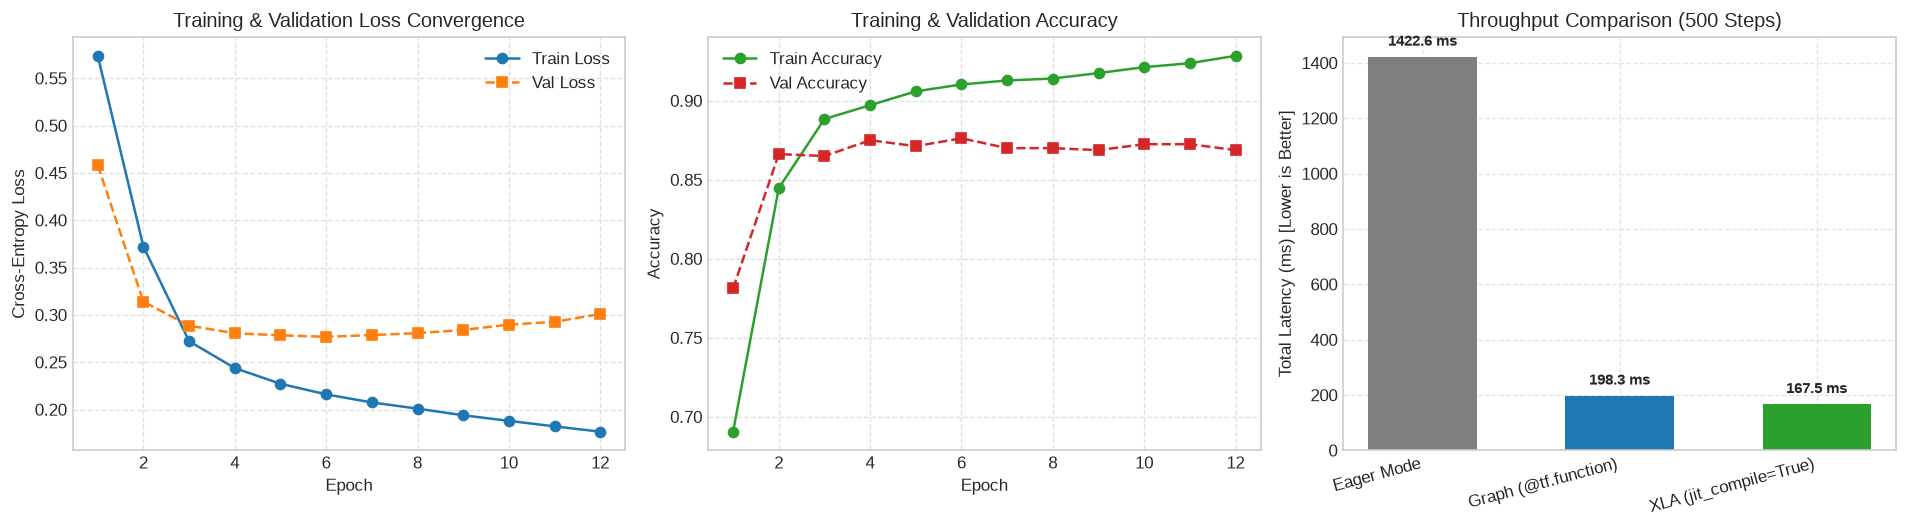

In [8]:
# Benchmark functions
bench_model = keras.Sequential([
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10)
])
dummy_batch = tf.random.normal(shape=(128, 128))

# 1. Eager function
def eager_step(x):
    return bench_model(x, training=False)

# 2. Graph function
@tf.function
def graph_step(x):
    return bench_model(x, training=False)

# 3. XLA compiled function
@tf.function(jit_compile=True)
def xla_step(x):
    return bench_model(x, training=False)

# Warmup runs (critical to trigger graph tracing and XLA JIT compilation)
_ = eager_step(dummy_batch)
_ = graph_step(dummy_batch)
try:
    _ = xla_step(dummy_batch)
    xla_supported = True
except Exception as e:
    print(f"XLA JIT not available in this CPU environment: {e}")
    xla_supported = False

# Timing benchmark over N iterations
iterations = 500

# Benchmark Eager
t0 = time.perf_counter()
for _ in range(iterations):
    _ = eager_step(dummy_batch)
t_eager = (time.perf_counter() - t0) * 1000 # ms

# Benchmark Graph
t0 = time.perf_counter()
for _ in range(iterations):
    _ = graph_step(dummy_batch)
t_graph = (time.perf_counter() - t0) * 1000 # ms

modes = ["Eager Mode", "Graph (@tf.function)"]
times = [t_eager, t_graph]

if xla_supported:
    t0 = time.perf_counter()
    for _ in range(iterations):
        _ = xla_step(dummy_batch)
    t_xla = (time.perf_counter() - t0) * 1000
    modes.append("XLA (jit_compile=True)")
    times.append(t_xla)

# Benchmark tf.data: Unoptimized vs Optimized Prefetched pipeline
raw_ds = tf.data.Dataset.from_tensor_slices((X_synth, y_synth)).batch(64)
opt_ds = tf.data.Dataset.from_tensor_slices((X_synth, y_synth)).cache().batch(64).prefetch(tf.data.AUTOTUNE)

t0 = time.perf_counter()
for _ in range(3):
    for b in raw_ds: pass
t_raw_pipeline = (time.perf_counter() - t0) * 1000 / 3

t0 = time.perf_counter()
for _ in range(3):
    for b in opt_ds: pass
t_opt_pipeline = (time.perf_counter() - t0) * 1000 / 3

print(f"--- Execution Mode Latency ({iterations} batches) ---")
for m, t in zip(modes, times):
    print(f"  {m:25s}: {t:8.2f} ms ({iterations / (t / 1000):.1f} steps/sec)")
print(f"\n--- Data Pipeline Epoch Iteration Latency ---")
print(f"  Raw Dataset:       {t_raw_pipeline:.2f} ms")
print(f"  Cached + Prefetch: {t_opt_pipeline:.2f} ms ({t_raw_pipeline/t_opt_pipeline:.2f}x speedup)")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Training convergence
epochs_range = range(1, len(training_history["train_loss"]) + 1)
axes[0].plot(epochs_range, training_history["train_loss"], "o-", color="#1f77b4", label="Train Loss")
axes[0].plot(epochs_range, training_history["val_loss"], "s--", color="#ff7f0e", label="Val Loss")
axes[0].set_title("Training & Validation Loss Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Training accuracy
axes[1].plot(epochs_range, training_history["train_acc"], "o-", color="#2ca02c", label="Train Accuracy")
axes[1].plot(epochs_range, training_history["val_acc"], "s--", color="#d62728", label="Val Accuracy")
axes[1].set_title("Training & Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

# Plot 3: Execution mode benchmark comparison
bars = axes[2].bar(modes, times, color=["#7f7f7f", "#1f77b4", "#2ca02c"][:len(modes)], width=0.55)
axes[2].set_title(f"Throughput Comparison ({iterations} Steps)")
axes[2].set_ylabel("Total Latency (ms) [Lower is Better]")
axes[2].set_xticklabels(modes, rotation=15, ha="right")
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2.0, yval + (max(times)*0.02), f"{yval:.1f} ms", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Custom Training Step with Global Norm Gradient Clipping & LR Decay
**Problem Formulation**: In deep or recurrent architectures, exploding gradients ($\|\nabla_\theta L\|_2 \to \infty$) destabilize parameter updates. Implement a custom compiled training step that:
1. Calculates gradients with `tf.GradientTape`.
2. Computes the global $L_2$ gradient norm:

$$\|\mathbf{g}\|_2 = \sqrt{\sum_{i} \|\mathbf{g}_i\|_2^2}$$

3. Clips gradients to a maximum norm $C=1.0$ via `tf.clip_by_global_norm`:

$$\mathbf{g}_{\text{clipped}} = \mathbf{g} \cdot \frac{C}{\max(\|\mathbf{g}\|_2, C)}$$

4. Applies a `tf.keras.optimizers.schedules.ExponentialDecay` learning rate schedule.


In [9]:
# Exercise 1 Solution: Gradient Clipping with Global Norm & LR Decay

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.01,
    decay_steps=100,
    decay_rate=0.96,
    staircase=True
)
clipped_optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)
test_model = keras.Sequential([keras.layers.Dense(16, activation="relu"), keras.layers.Dense(1)])

@tf.function
def clipped_train_step(
    model: keras.Model,
    optimizer: tf.keras.optimizers.Optimizer,
    x: tf.Tensor,
    y: tf.Tensor,
    max_clip_norm: float = 1.0
) -> Tuple[tf.Tensor, tf.Tensor]:
    with tf.GradientTape() as tape:
        preds = model(x, training=True)
        loss = tf.reduce_mean(tf.square(preds - y))

    gradients = tape.gradient(loss, model.trainable_variables)
    
    # Calculate pre-clip global norm and apply clipping
    pre_clip_norm = tf.linalg.global_norm(gradients)
    clipped_grads, post_clip_norm = tf.clip_by_global_norm(gradients, clip_norm=max_clip_norm)
    
    optimizer.apply_gradients(zip(clipped_grads, model.trainable_variables))
    return loss, pre_clip_norm

# Test the clipped step with artificially large inputs that cause large gradients
x_large = tf.random.normal(shape=(32, 10)) * 50.0
y_large = tf.random.normal(shape=(32, 1)) * 50.0

loss_val, g_norm = clipped_train_step(test_model, clipped_optimizer, x_large, y_large, max_clip_norm=1.0)
print(f"Exercise 1 Verification:")
print(f"  Step Loss:               {loss_val.numpy():.4f}")
print(f"  Pre-clip Gradient Norm:  {g_norm.numpy():.4f}")
print(f"  Current Scheduled LR:    {float(clipped_optimizer.learning_rate.numpy()):.6f}")


Exercise 1 Verification:
  Step Loss:               3160.2720
  Pre-clip Gradient Norm:  5795.9688
  Current Scheduled LR:    0.010000


#### Exercise 2: End-to-End High-Throughput `tf.data` Text/Token Pipeline
**Problem Formulation**: Construct a production data pipeline for sequence data that:
1. Takes variable-length integer token sequences.
2. Applies a padding and truncation transformation to a fixed length $L=32$.
3. Evaluates pipeline throughput in samples per second across unbatched vs. batched + prefetched configurations.


In [10]:
# Exercise 2 Solution: High-Throughput Token Preprocessing Pipeline

def build_token_pipeline(num_sequences: int = 5000, max_seq_len: int = 32, batch_size: int = 64) -> tf.data.Dataset:
    # Synthetic variable-length token arrays
    token_lists = [np.random.randint(1, 1000, size=np.random.randint(10, 50)).astype(np.int32) for _ in range(num_sequences)]
    labels = np.random.randint(0, 2, size=num_sequences).astype(np.int32)

    # Pad/truncate helper function
    def pad_truncate_py(seq):
        seq = seq[:max_seq_len]
        if len(seq) < max_seq_len:
            seq = np.pad(seq, (0, max_seq_len - len(seq)), mode="constant", constant_values=0)
        return seq

    def tf_mapper(seq_ragged, label):
        # Using tf.numpy_function or native TF padding
        padded_seq = tf.numpy_function(pad_truncate_py, [seq_ragged], tf.int32)
        padded_seq.set_shape([max_seq_len])
        return padded_seq, label

    # Convert ragged array representation to dataset
    raw_dataset = tf.data.Dataset.from_generator(
        lambda: zip(token_lists, labels),
        output_signature=(
            tf.TensorSpec(shape=(None,), dtype=tf.int32),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )

    pipeline = (
        raw_dataset
        .map(tf_mapper, num_parallel_calls=tf.data.AUTOTUNE)
        .cache()
        .shuffle(buffer_size=1000)
        .batch(batch_size, drop_remainder=True)
        .prefetch(tf.data.AUTOTUNE)
    )
    return pipeline

token_ds = build_token_pipeline(num_sequences=2000, max_seq_len=32, batch_size=64)

# Measure throughput
t_start = time.perf_counter()
total_samples = 0
for batch_tokens, batch_labels in token_ds:
    total_samples += batch_tokens.shape[0]
total_time = time.perf_counter() - t_start

print(f"Exercise 2 Verification:")
print(f"  Processed {total_samples} sequence samples in {total_time:.4f} seconds")
print(f"  Throughput: {total_samples / total_time:.1f} samples/sec")
print(f"  Sample Batch Shape: {batch_tokens.shape}, Dtype: {batch_tokens.dtype}")


E0000 00:00:1794179793.041628     248 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}
I0000 00:00:1794179793.047694     248 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


Exercise 2 Verification:
  Processed 1984 sequence samples in 0.4838 seconds
  Throughput: 4100.9 samples/sec
  Sample Batch Shape: (64, 32), Dtype: <dtype: 'int32'>


### Challenge Problems

#### Challenge 1: Custom Stateful Keras Layer with Trainable Weights & Non-Trainable Moving Average
**Problem Formulation**:
Implement a custom Keras layer, `AdaptiveFeatureScaler`, subclassing `keras.layers.Layer`, that maintains:
1. **Trainable parameter $\mathbf{\gamma}$** (scale vector initialized to ones).
2. **Trainable parameter $\mathbf{\beta}$** (shift vector initialized to zeros).
3. **Non-trainable state variable $\mathbf{\mu}_{\text{ema}}$**: An exponential moving average of the input feature means:

$$\mathbf{\mu}_{\text{ema}}^{(t)} = \alpha \cdot \mathbf{\mu}_{\text{ema}}^{(t-1)} + (1 - \alpha) \cdot \mathbb{E}[\mathbf{x}]$$

Where $\alpha = 0.9$ is the momentum factor. During `training=True`, update $\mathbf{\mu}_{\text{ema}}$; during `training=False`, use the frozen moving average for centering.


In [11]:
# Challenge 1 Solution: Custom Stateful Keras Layer

class AdaptiveFeatureScaler(keras.layers.Layer):
    def __init__(self, momentum: float = 0.9, **kwargs):
        super().__init__(**kwargs)
        self.momentum = momentum

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        
        # Trainable parameters
        self.gamma = self.add_weight(
            name="gamma",
            shape=(feature_dim,),
            initializer="ones",
            trainable=True
        )
        self.beta = self.add_weight(
            name="beta",
            shape=(feature_dim,),
            initializer="zeros",
            trainable=True
        )
        
        # Non-trainable state variable (moving average)
        self.moving_mean = self.add_weight(
            name="moving_mean",
            shape=(feature_dim,),
            initializer="zeros",
            trainable=False
        )
        super().build(input_shape)

    def call(self, inputs, training=None):
        if training:
            batch_mean = tf.reduce_mean(inputs, axis=0)
            # Update moving average state in-place
            new_mean = self.momentum * self.moving_mean + (1.0 - self.momentum) * batch_mean
            self.moving_mean.assign(new_mean)
            centered = inputs - batch_mean
        else:
            centered = inputs - self.moving_mean

        return self.gamma * centered + self.beta

# Verification
scaler_layer = AdaptiveFeatureScaler(momentum=0.85)
test_inputs = tf.constant([[10.0, 20.0], [12.0, 24.0]], dtype=tf.float32)

# Training forward pass (updates moving_mean)
out_train = scaler_layer(test_inputs, training=True)
print("Challenge 1 Verification:")
print(f"  Trainable Variables:     {[v.name for v in scaler_layer.trainable_variables]}")
print(f"  Non-Trainable Variables: {[v.name for v in scaler_layer.non_trainable_variables]}")
print(f"  Moving Mean after Step:  {scaler_layer.moving_mean.numpy()}")
print(f"  Training Output:\n{out_train.numpy()}")

# Inference forward pass (uses frozen moving_mean)
out_infer = scaler_layer(test_inputs, training=False)
print(f"  Inference Output:\n{out_infer.numpy()}")


Challenge 1 Verification:
  Trainable Variables:     ['gamma', 'beta']
  Non-Trainable Variables: ['moving_mean']
  Moving Mean after Step:  [1.6500001 3.3000002]
  Training Output:
[[-1. -2.]
 [ 1.  2.]]
  Inference Output:
[[ 8.35 16.7 ]
 [10.35 20.7 ]]


#### Challenge 2: Diagnosing Graph Retracing Bugs in `@tf.function`
**Problem Formulation**:
A common silent performance bug in TensorFlow is **accidental graph retracing**. When a Python integer or float (instead of a `tf.Tensor`) is passed to a `@tf.function`, TensorFlow interprets each unique Python value as a new signature and recompiles a brand new `ConcreteFunction`, destroying performance.

1. Implement a diagnostic function that exposes Python side-effect tracing.
2. Demonstrate how passing raw Python scalars triggers repeated retracing.
3. Fix the retracing bug using explicit `tf.TensorSpec` signatures.


In [12]:
# Challenge 2 Solution: Graph Retracing Diagnostic & Resolution

retrace_counter = 0

@tf.function
def flawed_scalar_step(x: tf.Tensor, scale_factor: float) -> tf.Tensor:
    global retrace_counter
    retrace_counter += 1
    print(f"  [AutoGraph Trace Notice] Retracing graph #{retrace_counter}! (Side effect executed)")
    return x * tf.cast(scale_factor, tf.float32)

print("Challenge 2 Diagnostic - Flawed Execution (Passing Python floats):")
retrace_counter = 0
dummy_x = tf.constant([1.0, 2.0, 3.0])

# Each distinct Python scalar triggers a full graph retrace!
for factor in [1.5, 2.0, 2.5, 3.0]:
    _ = flawed_scalar_step(dummy_x, factor)
print(f"Total Graph Compilations with Python Floats: {retrace_counter} (Expected: 4 retraces - SEVERE BOTTLENECK)")

# FIX: Strict input signature via TensorSpec
fixed_retrace_counter = 0

@tf.function(input_signature=[
    tf.TensorSpec(shape=[None], dtype=tf.float32),
    tf.TensorSpec(shape=[], dtype=tf.float32)
])
def fixed_scalar_step(x: tf.Tensor, scale_factor: tf.Tensor) -> tf.Tensor:
    global fixed_retrace_counter
    fixed_retrace_counter += 1
    print(f"  [AutoGraph Fixed Notice] Tracing static graph #{fixed_retrace_counter}!")
    return x * scale_factor

print("\nChallenge 2 Resolution - Optimized Execution (Using TensorSpec Signature):")
fixed_retrace_counter = 0
for factor in [1.5, 2.0, 2.5, 3.0]:
    # Pass as tf.constant tensor
    _ = fixed_scalar_step(dummy_x, tf.constant(factor, dtype=tf.float32))

print(f"Total Graph Compilations with TensorSpec Signature: {fixed_retrace_counter} (Optimal: exactly 1 trace)")


Challenge 2 Diagnostic - Flawed Execution (Passing Python floats):
  [AutoGraph Trace Notice] Retracing graph #1! (Side effect executed)
  [AutoGraph Trace Notice] Retracing graph #2! (Side effect executed)
  [AutoGraph Trace Notice] Retracing graph #3! (Side effect executed)
  [AutoGraph Trace Notice] Retracing graph #4! (Side effect executed)
Total Graph Compilations with Python Floats: 4 (Expected: 4 retraces - SEVERE BOTTLENECK)

Challenge 2 Resolution - Optimized Execution (Using TensorSpec Signature):
  [AutoGraph Fixed Notice] Tracing static graph #1!
Total Graph Compilations with TensorSpec Signature: 1 (Optimal: exactly 1 trace)


### Further Reading & Technical References
1. **TensorFlow Core Guide**: [Better Performance with tf.function](https://www.tensorflow.org/guide/function) — In-depth analysis of polymorphism, concrete functions, and AutoGraph tracing semantics.
2. **Keras 3 Guide**: [The Multi-Backend Deep Learning Framework](https://keras.io/keras_3/) — How Keras 3 provides multi-framework portability across TensorFlow, PyTorch, and JAX.
3. **XLA Compiler Architecture**: [Accelerated Linear Algebra Documentation](https://www.tensorflow.org/xla) — Just-in-time and Ahead-of-time compilation for neural networks.
4. **tf.data Performance Best Practices**: [Inside TensorFlow: tf.data](https://www.tensorflow.org/guide/data_performance) — Multi-threading, memory caching, and IO pipeline optimization.
5. **TensorFlow Serving**: [Architecture Overview & gRPC Client Specifications](https://www.tensorflow.org/tfx/serving/architecture) — High-throughput zero-downtime model lifecycle management.
